# 3. Sentence embeddings (WELFake)

How the articles are turned into sentence embeddings and what the model sees of each article. The embeddings will
be used for **paraphrase detection** (the second tier of the duplicate groups), **clustering** (input to K-means)
and **features** (input to the classifier); those uses come in later sections. The code is in
`fake_news.features.embeddings`; the embeddings are built by `scripts/compute_embeddings.py`.

**Principle:** *the encoder is pretrained and never fitted on our data.* Embeddings are therefore computed once for
all 62,525 cleaned articles, before and independently of any split. Everything fitted **on** the embeddings (PCA,
K-means, classifiers) is fitted on `train` only.

| Section | Content |
|---|---|
| 1 | The model and why it fits the task |
| 2 | Input and truncation: what the model sees of each article |
| 3 | Computing the embeddings and checks |
| 4 | Do the embeddings capture meaning? Nearest neighbours |
| 5 | Outputs and how to use them |

**Before running:** `pip install -e .` and `pip install sentence-transformers` (see the README). The embeddings are
committed to git, so normally nothing needs to be computed. If they are missing or outdated, section 3 builds them
(or run `python3 scripts/compute_embeddings.py`): minutes on a GPU (Colab, DTU HPC), an hour or more on a laptop
CPU. With the cache in place the notebook runs in about a minute. Figures are saved to `reports/figures/`.

In [1]:
%load_ext autoreload
%autoreload 2

import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fake_news import config
from fake_news.data import load_clean
from fake_news.features import embeddings as emb

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 220)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ---- notebook helpers (same style as notebooks 01 and 02) ----
REAL, FAKE = "#2a78d6", "#eb6834"  # real = blue, fake = orange in every figure
INK2, MUTED, GRID, AXIS, SURFACE = "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150)


def short(s, n=110):
    return textwrap.shorten(str(s), n, placeholder=" …")


clean = load_clean(columns=["title", "content"])          # doc_id, title, content, is_fake
by_id = clean.set_index("doc_id")
print(f"{len(clean):,} cleaned articles, {clean.is_fake.mean():.1%} fake")

62,525 cleaned articles, 44.4% fake


## 1. The model and why it fits the task

**Sentence-BERT** (Reimers & Gurevych, 2019) is a BERT-type transformer fine-tuned so that texts with similar
meaning get vectors with high cosine similarity. A text goes through the transformer once; its token vectors are
averaged (*mean pooling*) into one fixed-length vector. Plain BERT is not trained for this: its averaged vectors
are poor similarity measures, and comparing two texts with BERT as a cross-encoder needs one forward pass per
*pair*, about 2 billion passes for our articles. With Sentence-BERT it is one pass per *article*, and similarity is
a dot product.

**How it is trained.** Pairs of texts that belong together (question/answer, title/body, paraphrases, a post and
its reply) are encoded by the same network (a *siamese* setup). A contrastive loss pulls each pair together and
pushes it away from the other texts in the batch (*multiple-negatives ranking loss*: for pair (a, b), every other
b in the batch is a negative). After enough pairs, distance in the vector space tracks similarity in meaning.

**The model we use: `all-MiniLM-L6-v2`.** According to its model card: a 6-layer MiniLM (a distilled, smaller
BERT, about 22M parameters), fine-tuned with that contrastive objective on more than 1 billion text pairs
(Reddit, S2ORC citation pairs, WikiAnswers, Stack Exchange, MS MARCO, NLI data, …). It outputs 384-dimensional
vectors and truncates input at 256 word pieces.

**Why it suits this project.**
- *Meaning, not wording.* MinHash compares shingles, so a story rewritten in other words is invisible to it; the
  embeddings still place it next to the original.
- *Dense and low-dimensional.* 384 dimensions suit K-means far better than a sparse TF-IDF space with 100k+
  dimensions and can be added directly to the classifier input.
- *No leakage.* It is pretrained on other data and never fitted on WELFake.

**Limitations.** English only (non-English articles were dropped in cleaning, G3); only the first 256 word pieces
are read (section 2); trained on general web text, not news; similar meaning says nothing about truth.

In [2]:
encoder = emb.load_encoder()
tok = encoder.tokenizer
display(pd.Series({
    "model": emb.MODEL_NAME,
    "embedding dimension": encoder.get_sentence_embedding_dimension(),
    "max input (word pieces)": encoder.max_seq_length,
    "device": str(encoder.device),
}).to_frame("value"))

# `content` is lower-cased. That loses nothing if the tokenizer is uncased: same word pieces either way.
example = "WASHINGTON - President Trump said on Thursday"
print("uncased tokenizer:", tok.tokenize(example) == tok.tokenize(example.lower()))
print(tok.tokenize(example.lower()))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

C:\Users\alber\AppData\Local\Temp\ipykernel_34812\151407638.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "embedding dimension": encoder.get_sentence_embedding_dimension(),


,value
model,sentence-transformers/all-MiniLM-L6-v2
embedding dimension,384
max input (word pieces),256
device,cuda:0


uncased tokenizer: True
['washington', '-', 'president', 'trump', 'said', 'on', 'thursday']


The tokenizer is uncased, so the lower-cased shared `content` column gives exactly the same input as the original
casing would: we embed `content` like every other model. (Capitalization signals such as "REPORT:" vs "Report:",
discussed in notebook 02, therefore never reach the embeddings.)

## 2. Input and truncation: what the model sees of each article

The model reads at most 256 word pieces (about 180–200 words); the rest of an article is cut off. Token counts
on a random sample of 5,000 cleaned articles:

In [3]:
sample = clean.sample(n=min(5000, len(clean)), random_state=config.SEED)
lengths = emb.token_lengths(tok, emb.embedding_texts(sample))
L = pd.DataFrame({"tokens": lengths, "is_fake": sample.is_fake.to_numpy()})
L["truncated"] = L.tokens > emb.MAX_SEQ_LENGTH
L["share_read"] = np.minimum(1, emb.MAX_SEQ_LENGTH / L.tokens)

trunc = L.groupby(L.is_fake.map({0: "real", 1: "fake"})).agg(
    articles=("tokens", "size"), median_tokens=("tokens", "median"), p90_tokens=("tokens", lambda s: s.quantile(0.9)),
    truncated=("truncated", "mean"), median_share_read=("share_read", "median")).reindex(["real", "fake"])
trunc.loc["all"] = [len(L), L.tokens.median(), L.tokens.quantile(0.9), L.truncated.mean(), L.share_read.median()]
display(trunc.style.format({"articles": "{:,.0f}", "median_tokens": "{:,.0f}", "p90_tokens": "{:,.0f}",
                            "truncated": "{:.1%}", "median_share_read": "{:.1%}"}))
display(Markdown(
    f"**{L.truncated.mean():.0%}** of the articles are longer than {emb.MAX_SEQ_LENGTH} word pieces; the median "
    f"article is read up to **{L.share_read.median():.0%}** of its length."))

,articles,median_tokens,p90_tokens,truncated,median_share_read
is_fake,,,,,
real,"2,763",542,"1,493",79.1%,47.2%
fake,"2,237",487,"1,250",81.5%,52.6%
all,"5,000",514,"1,417",80.2%,49.8%


**80%** of the articles are longer than 256 word pieces; the median article is read up to **50%** of its length.

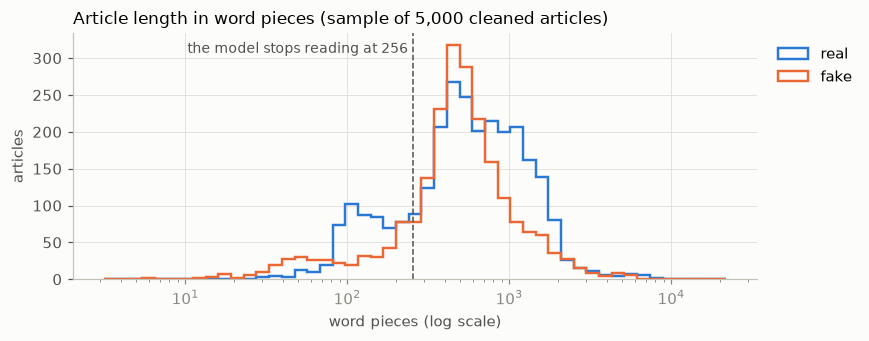

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(0.5, np.log10(max(L.tokens.max(), 300)), 50)
for y, name, color in ((0, "real", REAL), (1, "fake", FAKE)):
    ax.hist(L.tokens[L.is_fake == y], bins=bins, histtype="step", linewidth=1.6, color=color, label=name)
ax.axvline(emb.MAX_SEQ_LENGTH, color=INK2, linestyle="--", linewidth=1)
ax.text(emb.MAX_SEQ_LENGTH * 0.93, ax.get_ylim()[1] * 0.92, "the model stops reading at 256", color=INK2,
        fontsize=9, ha="right")
ax.set_xscale("log")
ax.set(title="Article length in word pieces (sample of 5,000 cleaned articles)", xlabel="word pieces (log scale)",
       ylabel="articles")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save(fig, "embeddings_token_lengths")
plt.show()

**Decision: truncate, title first.** `content` starts with the title, so the model always reads the headline and
the opening of the story. News is written as an inverted pyramid: the headline and first paragraphs carry who,
what and where, and the rest adds detail. That opening is what decides whether two articles tell the same story,
which is what paraphrase detection and topic clustering need. The alternative, embedding 256-token chunks and
averaging them, multiplies the runtime and blurs the vector with secondary details.

The flip side: the opening is also where the source markers sat (datelines, title suffixes), which is why the
embeddings must be built from the cleaned text.

## 3. Computing the embeddings and checks

`build_embeddings` loads the cache if it matches the current cleaned data (it compares against
`clean_fingerprint.json`), otherwise it computes it.

In [5]:
meta = emb.build_embeddings(encoder=encoder)
display(pd.Series({
    "articles": f"{meta['n_docs']:,}",
    "device": meta["device"],
    "embedding time": f"{meta['seconds'] / 60:.1f} min ({meta['docs_per_second']:,.0f} articles/s)",
    "stored as": f"{meta['stored_as']} on disk, float32 when loaded",
    "built": meta["created"],
    "versions": ", ".join(f"{k} {v}" for k, v in meta["versions"].items()),
}).to_frame("value"))
for line in emb.check_embeddings():
    print("ok ", line)
E, E_ids = emb.load_embeddings()

minilm__clean.npy is up to date (62,525 articles); use rebuild=True to redo


,value
articles,"62,525"
device,cuda:0
embedding time,3.0 min (347 articles/s)
stored as,"float16 on disk, float32 when loaded"
built,2026-11-14T16:38:30+00:00
versions,"sentence_transformers 6.3.0, transformers 5.23.0, torch 2.15.0+cu132"


ok  cache matches the current cleaned data
ok  shape (62525, 384), one doc_id per row
ok  all values finite
ok  every vector has unit length (up to float16 rounding)
ok  doc_ids unique and sorted
ok  exactly the 62,525 cleaned articles


## 4. Do the embeddings capture meaning? Nearest neighbours

Before using the vectors, a qualitative check: for a few random articles, the three most similar other articles.
If the embeddings work, the neighbours are about the same event or topic even when the wording differs.

In [6]:
rng = np.random.default_rng(config.SEED)
rows = []
for i in rng.choice(len(E_ids), size=5, replace=False):
    sims = E @ E[i]
    sims[i] = -np.inf                      # not your own neighbour
    q = E_ids[i]
    rows.append({"": "QUERY", "doc_id": q, "label": "fake" if by_id.is_fake[q] else "real", "cosine": "",
                 "title": short(by_id.title[q])})
    for j in np.argsort(-sims)[:3]:
        d = E_ids[j]
        rows.append({"": "  neighbour", "doc_id": d, "label": "fake" if by_id.is_fake[d] else "real",
                     "cosine": f"{sims[j]:.3f}", "title": short(by_id.title[d])})
pd.DataFrame(rows).style.hide(axis="index").set_properties(subset=["title"], **{"text-align": "left"})

,doc_id,label,cosine,title
QUERY,54053,real,,Russia may impose counter-measures on U.S. after new sanctions: foreign ministry
neighbour,47697,real,0.769,Factbox: How proposed new U.S. sanctions would affect Russia
neighbour,49465,real,0.753,Factbox: What do the new U.S. sanctions on Russia target?
neighbour,3518,real,0.743,"Trump to sign Russia sanctions, Moscow retaliates"
QUERY,29434,real,,Back to school: China kindergarten weathers child abuse storm for now
neighbour,51656,real,0.856,China kindergarten sex abuse and 'needlemarks' claims prompt police probe
neighbour,60282,real,0.788,Beijing kindergartens get permanent inspectors after abuse scandal: Xinhua
neighbour,51865,real,0.786,China's RYB Education fires head of Beijing kindergarten embroiled in abuse scandal
QUERY,45017,real,,"New Kosovo PM pledges dialogue with Serbia, graft fight"
neighbour,5225,real,0.852,Former guerrilla coalition gets mandate to form Kosovo government


## 5. Outputs and how to use them

| File (in `data/processed/embeddings/`, in git) | Contents |
|---|---|
| `minilm__clean.npy` | float16 on disk (62,525 × 384, ~48 MB), returned as float32; L2-normalized, rows in `doc_id` order |
| `minilm__clean__doc_ids.npy` | the `doc_id` of each row |
| `minilm__clean.json` | model, settings, data fingerprint, runtime, library versions |

```python
from fake_news.features.embeddings import embeddings_for

X = embeddings_for(df.doc_id)       # aligned to any DataFrame of cleaned articles
```

- **K-means (Person 2):** cluster `embeddings_for(train.doc_id)`; assign val/test with `predict`. Vectors are
  normalized, so Euclidean K-means behaves like cosine (spherical) K-means.
- **Classifier features:** concatenate `embeddings_for(...)` with TF-IDF and the LSH neighbour features.
- **If the cleaning changes,** loading raises `StaleEmbeddingsError`; rerun `python3 scripts/compute_embeddings.py`
  and commit the three files again.

Paraphrase pairs for the duplicate groups (the embedding tier) come in a later section.